In [35]:
import joblib
import shap
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

In [36]:

current_dir = Path.cwd()

if (current_dir / "models").exists():
    project_root = current_dir
else:
    project_root = current_dir.parent


model_bundle = joblib.load(
    project_root / "models" / "random_forest_class_weight.joblib"
)

rf_model = model_bundle["model"]

print("Model loaded successfully!")
print("Model threshold:", model_bundle["threshold"])

Model loaded successfully!
Model threshold: 0.13


In [37]:
from pathlib import Path
import pandas as pd

# Locate project root
current_dir = Path.cwd()

if (current_dir / "data").exists():
    project_root = current_dir
else:
    project_root = current_dir.parent

# Load processed training data
data_dir = project_root / "data" / "processed"

x_train = pd.read_csv(data_dir / "x_train.csv")
y_train = pd.read_csv(data_dir / "y_train.csv")

# Remove unwanted index column if present
x_train = x_train.loc[:, ~x_train.columns.str.startswith("Unnamed:")]

print("Training data loaded successfully!")
print("X_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)
print(x_train.head())

Training data loaded successfully!
X_train shape: (8000, 7)
y_train shape: (8000, 1)
  Type  Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
0    M                302.0                    310.9                    1456   
1    M                297.0                    308.3                    1399   
2    M                301.0                    311.6                    1357   
3    L                298.9                    309.8                    1411   
4    L                297.1                    308.5                    1733   

   Torque [Nm]  Tool wear [min]  Temperature difference  
0         47.2               54                     8.9  
1         46.4              132                    11.3  
2         45.6              137                    10.6  
3         56.3               84                    10.9  
4         28.7               50                    11.4  


In [38]:

preprocessor = rf_model.named_steps["preprocessor"]
classifier = rf_model.named_steps["model"]

# Transform training data
X_transformed = preprocessor.transform(x_train)

# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Convert to DataFrame
X_shap = pd.DataFrame(
    X_transformed,
    columns=feature_names
)

print("Transformed shape:", X_shap.shape)
print("Feature names:", list(feature_names))


Transformed shape: (8000, 9)
Feature names: ['cat__Type_H', 'cat__Type_L', 'cat__Type_M', 'num__Air temperature [K]', 'num__Process temperature [K]', 'num__Rotational speed [rpm]', 'num__Torque [Nm]', 'num__Tool wear [min]', 'num__Temperature difference']


In [39]:
# Select a sample of 500 rows for SHAP analysis
X_sample = X_shap.sample(
    n=min(500, len(X_shap)),
    random_state=42
)

# Create SHAP Tree Explainer
explainer = shap.TreeExplainer(classifier)

# Calculate SHAP values
shap_values = explainer.shap_values(X_sample)

print("SHAP values calculated successfully!")
print("Output type:", type(shap_values))

if isinstance(shap_values, list):
    print("Positive class shape:", shap_values[1].shape)
else:
    print("SHAP output shape:", shap_values.shape)

SHAP values calculated successfully!
Output type: <class 'numpy.ndarray'>
SHAP output shape: (500, 9, 2)


In [40]:
positive_shap_values= shap_values[:, :, 1]
positive_shap_values

array([[-9.18302983e-05, -9.41088615e-03, -5.83307171e-03, ...,
        -1.83833414e-01, -6.94243281e-02,  6.12117647e-02],
       [-8.59079496e-04,  1.39314294e-03, -8.39063297e-04, ...,
        -1.87350153e-01, -9.24152529e-02, -4.03968294e-02],
       [-4.28320212e-04,  2.02620388e-03, -8.60159758e-04, ...,
        -1.95716780e-01, -9.38440177e-02, -4.41545093e-02],
       ...,
       [-1.58515948e-04,  3.88838645e-05, -7.27619178e-03, ...,
        -6.77227140e-02, -1.57406226e-01,  6.41533748e-02],
       [-2.74816202e-04,  4.40531181e-03, -3.41320565e-04, ...,
        -1.28773094e-01, -1.97204585e-01, -1.23823828e-01],
       [-9.40641642e-04, -9.02342497e-03, -6.46732966e-03, ...,
        -1.66932473e-01, -9.00266775e-02, -4.12239379e-02]],
      shape=(500, 9))

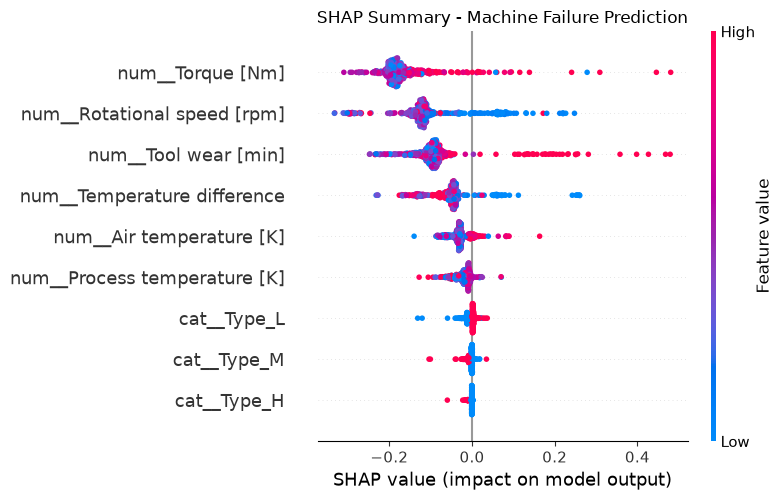

In [41]:
shap.summary_plot(
    positive_shap_values,
    X_sample,
    show=False
)

plt.title("SHAP Summary - Machine Failure Prediction")
plt.tight_layout()
plt.savefig(
    project_root / "reports" / "summary_plot.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

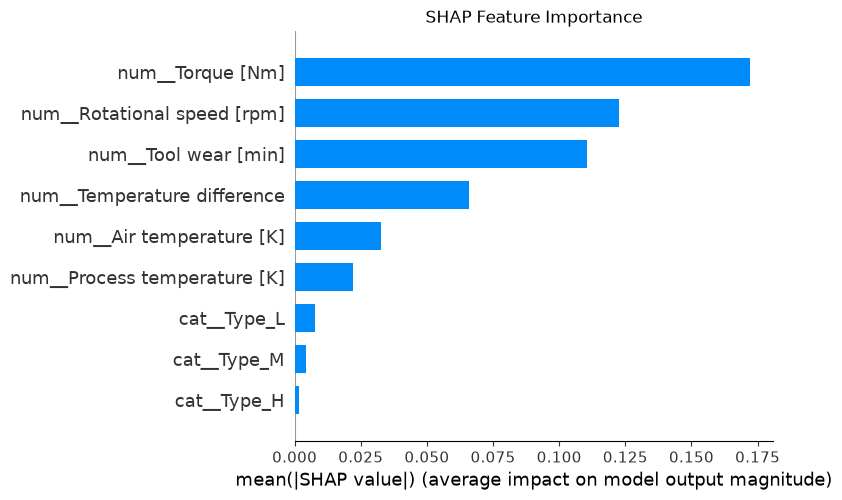

In [42]:
shap.summary_plot(
    positive_shap_values,
    X_sample,
    plot_type="bar",
    show=False
)

plt.title("SHAP Feature Importance")
plt.tight_layout()

plt.savefig(
    project_root / "reports" / "shap_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [43]:
import numpy as np
import pandas as pd

# Calculate mean absolute SHAP value for each feature
shap_importance = pd.DataFrame({
    "Feature": X_sample.columns,
    "Mean_SHAP_Importance": np.abs(
        positive_shap_values
    ).mean(axis=0)
})

# Sort from highest to lowest importance
shap_importance = shap_importance.sort_values(
    by="Mean_SHAP_Importance",
    ascending=False
).reset_index(drop=True)

# Display ranking
shap_importance.index = shap_importance.index + 1

print("MACHINE FAILURE - SHAP FEATURE IMPORTANCE")
(shap_importance)

MACHINE FAILURE - SHAP FEATURE IMPORTANCE


,Feature,Mean_SHAP_Importance
1,num__Torque [Nm],0.172195
2,num__Rotational speed [rpm],0.122618
3,num__Tool wear [min],0.110470
4,num__Temperature difference,0.065831
5,num__Air temperature [K],0.032672
6,num__Process temperature [K],0.022120
7,cat__Type_L,0.007645
8,cat__Type_M,0.004272
9,cat__Type_H,0.001652


In [44]:
import joblib

model_path = (
    project_root
    / "models"
    / "random_forest_class_weight.joblib"
)

# Load saved model bundle
deployment_bundle = joblib.load(model_path)

# Extract components
deployment_model = deployment_bundle["model"]
deployment_threshold = deployment_bundle["threshold"]

print("MODEL DEPLOYMENT VERIFICATION")
print("--------------------------------")
print("Model:", deployment_bundle["model_name"])
print("Threshold:", deployment_threshold)
print("Model type:", type(deployment_model))
print("Classes:", deployment_model.classes_)

assert deployment_threshold == 0.13
assert hasattr(deployment_model, "predict_proba")

print("\nModel bundle verified successfully!")

MODEL DEPLOYMENT VERIFICATION
--------------------------------
Model: Random Forest - Class Weight
Threshold: 0.13
Model type: <class 'sklearn.pipeline.Pipeline'>
Classes: [0 1]

Model bundle verified successfully!


In [48]:
# Load test data
x_test = pd.read_csv(
    project_root / "data" / "processed" / "X_test.csv"
)

# Remove unwanted CSV index columns, if present
x_test = x_test.loc[
    :, ~x_test.columns.str.startswith("Unnamed:")
]

print("Test data shape:", x_test.shape)
print("Input columns:", x_test.columns.tolist())

Test data shape: (2000, 7)
Input columns: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Temperature difference']


In [ ]:
# Select five sample machines
sample_machines = x_test.iloc[:5].copy()

# Get failure probabilities
probabilities = deployment_model.predict_proba(
    sample_machines
)

# Locate the probability column for class 1
failure_class_index = list(
    deployment_model.classes_
).index(1)

failure_probabilities = probabilities[
    :, failure_class_index
]

# Apply the saved threshold
predictions = (
    failure_probabilities >= deployment_threshold
).astype(int)


results = pd.DataFrame({
    "Failure Probability": failure_probabilities,
    "Prediction": predictions
})

results["Status"] = results["Prediction"].map({
    0: "No Failure",
    1: "Machine Failure"
})

(results)

print("Prediction pipeline tested successfully!")

,Failure Probability,Prediction,Status
0,0.38,1,Machine Failure
1,0.00,0,No Failure
2,0.27,1,Machine Failure
3,0.01,0,No Failure
4,0.08,0,No Failure


Prediction pipeline tested successfully!
